In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [13]:
# --- load (given) ---
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("raw shapes:", x_train.shape, y_train.shape)

# Q1a) Normalise pixels to [0, 1]
PIXEL_MAX = 255.0        # TODO (Q1a): the largest pixel value
x_train = x_train / PIXEL_MAX
x_test  = x_test  / PIXEL_MAX

# Q1b) Reshape to (samples, time_steps, features). Fill time_steps and features.
TIME_STEPS =28        # TODO (Q1b): number of rows read as time steps
FEATURES   = 28         # TODO (Q1b): number of pixels per row
x_train = x_train.reshape((x_train.shape[0], TIME_STEPS, FEATURES))
x_test  = x_test.reshape((x_test.shape[0],  TIME_STEPS, FEATURES))

# Q1c) One-hot encode the labels
NUM_CLASSES = 10       # TODO (Q1c): number of digit classes
y_train = to_categorical(y_train, NUM_CLASSES)
y_test  = to_categorical(y_test,  NUM_CLASSES)

print("prepared:", x_train.shape, y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
raw shapes: (60000, 28, 28) (60000,)
prepared: (60000, 28, 28) (60000, 10)


In [14]:
assert x_train.max() <= 1.0 and x_train.min() >= 0.0, "pixels not in [0,1]"
assert x_train.shape[1:] == (28, 28), "sequence shape should be (28, 28)"
assert y_train.shape[1] == 10, "labels should be one-hot with 10 columns"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


In [15]:
model = models.Sequential()

# Q2a) LSTM layer: fill the number of units and the input_shape
LSTM_UNITS = 128        # TODO (Q2a): number of LSTM memory units
model.add(layers.LSTM(LSTM_UNITS,
                      activation='relu',
                      input_shape=(28,28)))   # TODO (Q2a): (time_steps, features)

# Q2b) Output layer: one neuron per class, softmax activation
OUT_UNITS = 10         # TODO (Q2b): number of output neurons
model.add(layers.Dense(OUT_UNITS, activation='softmax'))   # TODO (Q2b): activation name as a string

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,674 (319.04 KB)

 Trainable params: 81,674 (319.04 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Q3a) Compile — fill optimiser, loss, and metric
model.compile(optimizer='adam',        # TODO (Q3a): optimiser name as a string
              loss='categorical_crossentropy',             # TODO (Q3a): loss name as a string
              metrics=['accuracy'])        # TODO (Q3a): metric name as a string

# Q3b) Train — fill epochs and batch_size
history = model.fit(x_train, y_train,
                    epochs=10,              # TODO (Q3b)
                    batch_size=64,          # TODO (Q3b)
                    validation_data=(x_test, y_test))

# Q3c) Evaluate
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.8088 - loss: 0.5940 - val_accuracy: 0.9470 - val_loss: 0.1677
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9609 - loss: 0.1295 - val_accuracy: 0.9629 - val_loss: 0.1220
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9715 - loss: 0.0917 - val_accuracy: 0.9727 - val_loss: 0.0886
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9789 - loss: 0.0706 - val_accuracy: 0.9795 - val_loss: 0.0635
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9808 - loss: 0.0618 - val_accuracy: 0.9832 - val_loss: 0.0549
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9832 - loss: 0.0534 - val_accuracy: 0.9826 - val_loss: 0.0566
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9861 - loss: 0.0456 - val_accuracy: 0.9801 - val_loss: 0.0616
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9870 - loss: 0.0402 - val_accuracy: 

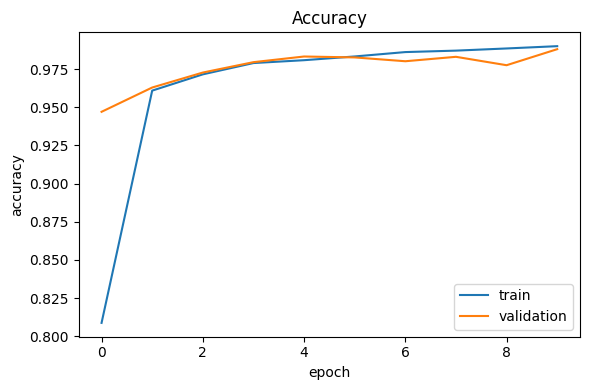

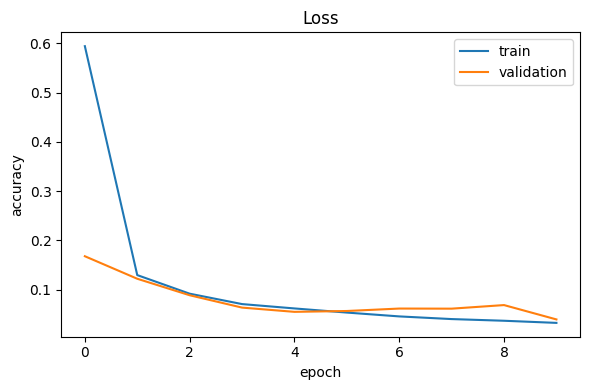

In [17]:
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'],     label='train')
plt.plot(history.history['val_accuracy'], label='validation')   # TODO (Q4): which key holds val accuracy?
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.title('Accuracy')
plt.tight_layout(); plt.show()


plt.figure(figsize=(6,4))
plt.plot(history.history['loss'],     label='train')
plt.plot(history.history['val_loss'], label='validation')   # TODO (Q4): which key holds val accuracy?
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.title('Loss')
plt.tight_layout(); plt.show()

1. We use (28, 28) because RNN processes the image row by row in 28 time steps, preserving the sequential structure, whereas MLP uses a flattened 784-pixel vector.

2. Hidden state carries information for current output and the next step, whereas cell state stores long-term important information.

3. Softmax is used because digit classification is a multi-class problem where only one digit (0–9) is correct, and softmax gives probabilities that sum to 1.

4. Changing LSTM(128) to LSTM(32) reduces the parameter count and training time, but accuracy may decrease because the model has less learning capacity.

5. Tanh is recommended for LSTM because it keeps values between -1 and +1, providing stable memory updates; accuracy may vary slightly.